In [1]:
import baostock as bs
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.sans-serif'] = ['Microsoft YaHei']
rcParams['axes.unicode_minus'] = False

from matplotlib import rcParams  # 字体
from unicodedata import normalize



In [2]:
def stock_screener(start_date, end_date, top_n=5):
    """
    股票筛选器函数
    参数:
         start_date:开始日期，格式'2026-05-01'
         end_date:结束日期'2026-07-21'
         top_n:返回前N只股票，默认5
     返回:
         df_sorted: 按涨幅排序的全部结果
         top_stocks: 排名前N的股票
     """

    print(f'开始筛选股票')
    print(f'{start_date}至 {end_date}')
    print(f'返回前 {top_n}名')
    print('-' * 40)

    lg = bs.login()
    if lg.error_code != '0':
        print(f'登陆失败：{lg.error_code}')
        return None,None,None

    rs = bs.query_hs300_stocks()
    stock_list = []
    while rs.error_code == '0' and rs.next():
        stock_list.append(rs.get_row_data())
    stock_df = pd.DataFrame(stock_list, columns=rs.fields)


    print(f'获取到{len(stock_df)}只沪深300股票')


    results = []
    for i, row in stock_df.iterrows():
        code = row['code']
        name = row['code_name']

        #每50只打印一次进度
        if i % 50 == 0:
            print(f'正在处理：{i + 1}/{len(stock_df)}')

        rs = bs.query_history_k_data_plus(
            code,
            'date,close',
            start_date=start_date,
            end_date=end_date,
            frequency="d"
        )
        data = []
        while rs.error_code == '0' and rs.next():
            data.append(rs.get_row_data())

        if len(data) >= 2:
            df = pd.DataFrame(data, columns=rs.fields)

            df['close'] = pd.to_numeric(df['close'])
            first_price = df['close'].iloc[0]
            last_price = df['close'].iloc[-1]
            pct = (last_price / first_price - 1) * 100

            results.append({
                'code': code,
                'name': name,
                'return': pct,
                'last_price': last_price
            })

        time.sleep(0.1)

    df_results = pd.DataFrame(results)
    df_sorted = df_results.sort_values('return', ascending=False)

    top_stocks = df_sorted.head(top_n)

    print('-' * 40)
    print(f'筛选成功!共 {len(df_results)}只股票数据')
    print(f'涨幅排名前{top_n}:')
    print(top_stocks[['code', 'name', 'return']])
    print()

    return df_sorted, top_stocks


def plot_top_stocks(top_stocks, start_date, end_date):
    """
    画股票走势图
    :param top_stocks:
    :param start_date:
    :param end_date:
    :return:
    """

    plt.figure(figsize=(12, 6))

    top_codes = top_stocks['code'].tolist()
    top_names = top_stocks['name'].tolist()
    for code, name in zip(top_codes, top_names):
        rs = bs.query_history_k_data_plus(
            code,
            'date,close',
            start_date=start_date,
            end_date=end_date,
            frequency="d"

        )
        data = []

        while rs.error_code == '0' and rs.next():
            data.append(rs.get_row_data())

        if len(data) >= 2:
            df = pd.DataFrame(data, columns=rs.fields)
            df['close'] = pd.to_numeric(df['close'])
            df['date'] = pd.to_datetime(df['date'])

            normalized = df['close'] / df['close'].iloc[0] * 100
            plt.plot(df['date'], normalized, label=name, linewidth=1.5)

    bs.logout()

    plt.title(f'TOP{len(top_stocks)}强势股票走势对比（归一化起点  = 100）')
    plt.xlabel('日期', fontsize=12)
    plt.ylabel('相对价格（起点 = 100）', fontsize=12)
    plt.legend(loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()



开始筛选股票
2026-06-01至 2026-07-21
返回前 5名
----------------------------------------
login success!
获取到300只沪深300股票
正在处理：1/300
正在处理：51/300
正在处理：101/300
正在处理：151/300
正在处理：201/300
正在处理：251/300
----------------------------------------
筛选成功!共 300只股票数据
涨幅排名前5:
          code  name     return
295  sz.301165  锐捷网络  80.553746
186  sh.688506  百利天恒  60.309641
176  sh.688082  盛美上海  51.522194
171  sh.688012  中微公司  49.410256
216  sz.000938  紫光股份  48.922414

logout success!


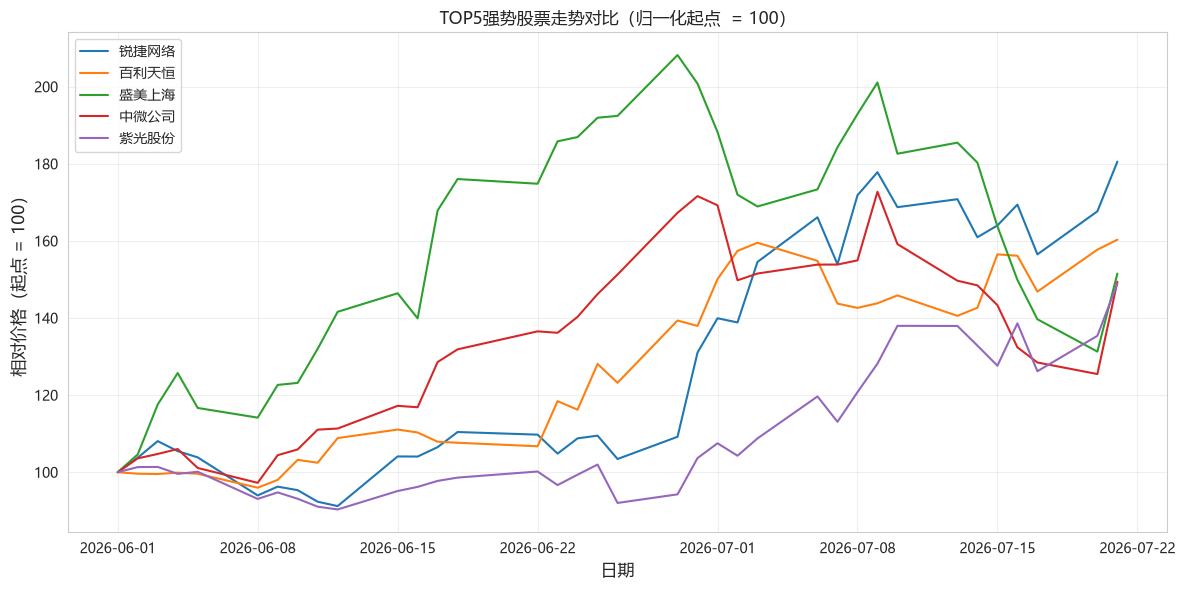

In [3]:
df_sorted,top_stocks = stock_screener('2026-06-01','2026-07-21',top_n=5)
plot_top_stocks(top_stocks,'2026-06-01','2026-07-21')

In [4]:
import baostock as bs

bs.login()

# 只拿1天的数据（最快）
rs = bs.query_history_k_data_plus(
    "sh.600036",
    "date,close",
    start_date="2026-07-21",
    end_date="2026-07-21",
    frequency="d"
)

data = []
while rs.error_code == '0' and rs.next():
    data.append(rs.get_row_data())

bs.logout()

print("数据:", data)

login success!
logout success!
数据: [['2026-07-21', '37.9900']]
